# Instance Cell Recognition Mask-RCNN-FPN model

reference : KChicken Detection/Segmentation - MaskRCNN Pytorch
https://www.kaggle.com/code/hayriyigit/chicken-detection-segmentation-maskrcnn-pytorch

- understood and implemented 0ct 14 JS

another reference:
- Model: Mask R-CNN, Kaiming He and Georgia Gkioxari and Piotr Dollár and Ross Girshick,2018, arXiv,cs.CV,https://arxiv.org/abs/1703.06870
- Model: Benchmarking detection transfer learning with vision transformers. Y Li, S Xie, X Chen, P Dollar, K He, R Girshick
arXiv preprint arXiv:2111.11429, 2021

In [1]:
import torch
import os

In [2]:
GPU_ID = 0 # GPUnumber to be used
DEVICE = torch.device(f'cuda:{GPU_ID}' if torch.cuda.is_available() else 'cpu')

###

image_size = 256  # choice is 256 or 512

###

LEARNING_RATE = 1e-5
WEIGHT_DECAY = 5e-4
BATCH_SIZE = 8 # choice is 16 or 8
NUM_EPOCHS = 700 # 77   or   777(for 512 data)
NUM_WORKERS = 4
CHECKPOINT_FILE = str(image_size)+"_multispecies_"+str(NUM_EPOCHS)+"_epoch.tar"  # renew name to make a new try
PIN_MEMORY = True
SAVE_MODEL = True
LOAD_MODEL = False
TRAIN_DIR = 'dataset/png_'+str(image_size)+'/image/train'
VALID_DIR = 'dataset/png_'+str(image_size)+'/image/valid'
TEST_DIR = 'dataset/png_'+str(image_size)+'/image/test'
IMAGE_SIZE = [image_size, image_size] # [512, 512] for 512 data

In [3]:
DEVICE

device(type='cuda', index=0)

In [4]:
import os
import cv2
import numpy as np
from pycocotools.coco import COCO
from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt

/home/nodokaizm/miniforge3/envs/rapids-24.12/lib/python3.12/site-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.7' (you have '2.0.5'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Define test image

In [5]:
from PIL import Image

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]
i = 4
img0 = Image.open(os.path.join(TEST_DIR,testfilename[i])).convert('RGB')
img0 = np.array(img0)
img = cv2.imread(os.path.join(TEST_DIR,testfilename[i]))


# DATASET

In [6]:
# read coco data and convert format for the _ResNet50_FPN model 

class CCDataset(Dataset):
    def __init__(self, mode = 'train', augmentation=None):
        if mode == 'train':
          self.dataset_path = TRAIN_DIR
          ann_path = os.path.join(TRAIN_DIR, 'train_annot_coco_'+str(image_size)+'.json')
        if mode == 'valid':
          self.dataset_path = VALID_DIR
          ann_path = os.path.join(VALID_DIR, 'valid_annot_coco_'+str(image_size)+'.json')
        if mode == 'test':
          self.dataset_path = TEST_DIR
          ann_path = os.path.join(TEST_DIR, 'test_annot_coco_'+str(image_size)+'.json')
        
        self.coco = COCO(ann_path)
        self.cat_ids = self.coco.getCatIds()
        self.augmentation=augmentation

    def __len__(self):
        return len(self.coco.imgs)
  
    def get_masks(self, index):
        ann_ids = self.coco.getAnnIds([index])
        anns = self.coco.loadAnns(ann_ids)
        masks=[]
        cell_type = []
        for j, ann in enumerate(anns):
            cell_type.append(anns[j]['category_id'])
            mask = self.coco.annToMask(ann)
            masks.append(mask)

        return masks,cell_type

    def get_boxes(self, masks, cell_type):
        valid_masks = []
        valid_types = []
        boxes = []

        for i in range(len(masks)):
            x, y, w, h = cv2.boundingRect(masks[i])
            if w > 0 and h > 0:
                boxes.append([x, y, x + w, y + h])
                valid_masks.append(masks[i])
                valid_types.append(cell_type[i])

        return np.array(boxes), np.array(valid_masks), np.array(valid_types)

    def __getitem__(self, index):
        img_info = self.coco.loadImgs([index])[0]
        image = cv2.imread(os.path.join(self.dataset_path, img_info['file_name']))
        masks, cell_type = self.get_masks(index)

        if self.augmentation:
            augmented = self.augmentation(image=image, masks=masks)
            image, masks = augmented['image'], augmented['masks']

        image = image.transpose(2, 0, 1) / 255.
        boxes, masks, cell_type = self.get_boxes(masks, cell_type)

        if len(boxes) == 0:
            return None

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(cell_type, dtype=torch.int64)
        masks = torch.as_tensor(masks, dtype=torch.uint8)
        image = torch.as_tensor(image, dtype=torch.float32)

        data = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks
        }

        return image, data

In [7]:
# To bypass shape errors
# Images contain different number of instances
def collate_fn(batch):
    # None の除去
    batch = list(filter(lambda x: x is not None, batch))
    if len(batch) == 0:
        return None  # または raise Exception("Empty batch")

    images = [b[0] for b in batch]
    targets = [b[1] for b in batch]
    images = torch.stack(images, dim=0)
    return images, targets

Followings are for augumentation

In [8]:
import albumentations as A
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(
        contrast_limit=0.2, brightness_limit=0.3, p=0.5),
    A.OneOf([
        A.ImageCompression(p=0.8),
        A.RandomGamma(p=0.8),
        A.Blur(p=0.8),
        A.Equalize(mode='cv',p=0.8)
    ], p=1.0),
    A.OneOf([
        A.ImageCompression(p=0.8),
        A.RandomGamma(p=0.8),
        A.Blur(p=0.8),
        A.Equalize(mode='cv',p=0.8),
    ], p=1.0)
])

# MODEL

#### model used is the improved version of Mask-RCNN-FPN.v2

In [9]:
import torch
from tqdm import tqdm
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2,MaskRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

progress = True

In [10]:
def get_model():
    #model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT) #pretrained=True
    model = maskrcnn_resnet50_fpn_v2(weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT) #pretrained=True
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(
            in_features, num_classes=1+4) 
    model.to(DEVICE)
    
    return model

In [11]:
def save_checkpoint(state, filename='./model/'+str(image_size)+'_mask_rcnn.tar'):
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    print("=> Model improved, Saving checkpoint")
    torch.save(state, filename)

In [12]:
def load_checkpoint(checkpoint, model, optimizer, lr):
    print("=> Loading checkpoint")
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])

    # If we don't do this then it will just have learning rate of old checkpoint
    # and it will lead to many hours of debugging \:
    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

## Train

In [13]:
train_dataset = CCDataset(mode='train', augmentation=transform)
train_loader = DataLoader(dataset=train_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=True,
                              num_workers=2,
                              pin_memory=PIN_MEMORY,
                              collate_fn=collate_fn)

valid_dataset = CCDataset(mode='valid')
valid_loader = DataLoader(dataset=valid_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=False,
                              pin_memory=PIN_MEMORY,
                              collate_fn=collate_fn)

loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


In [14]:
def train_one_epoch(loader, model, optimizer, device):
    #loop = tqdm(loader)
    loop = loader
    
    for batch_idx, (images, targets) in enumerate(loop):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

    #print(f"Total loss: {losses.item()}, ",end="")
    return losses.item()

In [15]:
best_vloss = np.inf
def validate(loader, model, optimizer, device, epoch):
    global best_vloss
    loop = loader
    running_vloss = 0
    for batch_idx, (images, targets) in enumerate(loop):
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        with torch.no_grad():
          loss_dict = model(images, targets)
        
        losses = sum(loss for loss in loss_dict.values())
        running_vloss += losses
        
    avg_vloss = running_vloss / (batch_idx + 1)
    
    #print(f"Avg Valid Loss: {avg_vloss}, ")
    if avg_vloss < best_vloss:
      best_vloss = avg_vloss
      if SAVE_MODEL:
            #print("")
            checkpoint = {
                "state_dict": model.state_dict(),
                "optimizer": optimizer.state_dict(),
            }
            ############  save_checkpoint 
            save_checkpoint(checkpoint, filename=f"./checkpoint/"+str(image_size)+"_multispecies_"+str(NUM_EPOCHS)+"_epoch.tar")   
    return avg_vloss

In [16]:
model = get_model()
optimizer = torch.optim.AdamW(params=model.parameters(),
                                  lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY
                                  )

In [17]:
if LOAD_MODEL and CHECKPOINT_FILE in os.listdir('./model'):
    print("Loading checkpoint")
    c_f = os.path.join('./model',CHECKPOINT_FILE)
    load_checkpoint(torch.load(c_f), model, optimizer, LEARNING_RATE)

In [18]:
def show_progress(frame, model,comment, epoch, total_loss, valid_loss, NUM_EPOCHS, keep_progress = False):

    model.train(False)
    images = cv2.resize(frame, IMAGE_SIZE, cv2.INTER_LINEAR)/255
    images = torch.as_tensor(images, dtype=torch.float32).unsqueeze(0)
    images = images.swapaxes(1, 3).swapaxes(2, 3)
    images = list(image.to(DEVICE) for image in images)
    
    with torch.no_grad():
        pred = model(images)

    cell_types = ['boundary', 'vessel','ray','fiber', 'parenchyma']
    cell_color = [(0,0,0),(1,159/255,155/255),(144/255,229/255,161/255),\
                  (161/255,201/255,244/255),(1,180/255,130/255)]
    im = images[0].swapaxes(0, 2).swapaxes(0, 1).detach().cpu().numpy().astype(np.float32)
    im2 = np.zeros_like(im).astype(np.float32)
       
    for i in range(len(pred[0]['masks'])):
        msk=pred[0]['masks'][i,0].detach().cpu().numpy()
        scr=pred[0]['scores'][i].detach().cpu().numpy()
        box=pred[0]['boxes'][i].detach().cpu().numpy()
        cell_name=pred[0]['labels'][i].detach().cpu().numpy()
        if scr>0.3 :  #0.9
            cv2.putText(im, str(cell_types[cell_name])+"_"+"{0:.2f}%".format(scr*100), (int(box[0]+5), int(box[1])+15), cv2.FONT_HERSHEY_SIMPLEX,
                         0.2, cell_color[cell_name], 1, cv2.LINE_AA)
            #cv2.putText(im, "un"+"_"+"{0:.2f}%".format(scr*100), (int(box[0]+5), int(box[1])+15), cv2.FONT_HERSHEY_SIMPLEX,
            #            0.2, cell_color[cell_name], 1, cv2.LINE_AA)

            im2[:, :, :][msk > 0.87] = cell_color[cell_name]   ################
    im_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1,2,figsize=(8,4)) 
    plt.cla()
    ax[0].imshow((cv2.addWeighted(im_rgb, 0.5, im2, 0.5, 0)*255).astype(np.uint8))
    ax[0].set_title(comment, fontsize = 8) 
    #ax[0].axis('off')
    ax[1].set_xlim(0,NUM_EPOCHS)
    ax[1].set_xlabel('epoch')
    ax[1].set_ylabel('loss')
    ax[1].plot(range(epoch+1),total_loss, c='red', label='train')
    ax[1].plot(range(epoch+1),valid_loss, c='blue', label='validation')
    plt.tight_layout()
    if keep_progress == True:
        buf = io.BytesIO() # prepare buffer
        plt.savefig(buf, format='png') # store in the buffer
        enc = np.frombuffer(buf.getvalue(), dtype=np.uint8) # read from buffer
        dst = cv2.imdecode(enc, 1) # decoding
        dst = dst[:,:,::-1] # BGR->RGB
        plt.show()
        #
        return dst       
    else:
        print(comment)
        
    

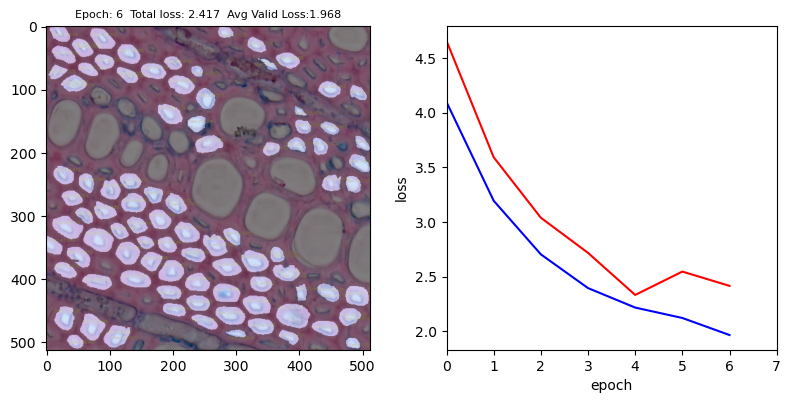

In [19]:
from IPython import display
import io


keep_progress = True
total_loss = []
valid_loss = []
prog_report = []
for epoch in range(NUM_EPOCHS):
    model.train()
    
    tloss = train_one_epoch(train_loader, model, optimizer, DEVICE)
    vloss = validate(valid_loader, model, optimizer, DEVICE, epoch)
    total_loss.append(tloss)
    valid_loss.append(vloss.cpu().item())
   
    comment = f"Epoch: {epoch}"+"  Total loss: "+"{:.3f}".format(tloss)+"  Avg Valid Loss:"+"{:.3f}".format(vloss)
    print(comment)
    display.clear_output(wait=True)
    prog_shot = show_progress(img, model, comment, epoch, total_loss, valid_loss, NUM_EPOCHS,keep_progress =True)
    prog_report.append(prog_shot)



In [20]:
print("Training finished!")

Training finished!


In [21]:
import imageio
imageio.mimsave('./output/result'+str(image_size)+'_progress_report.gif', prog_report,'GIF', fps=5)

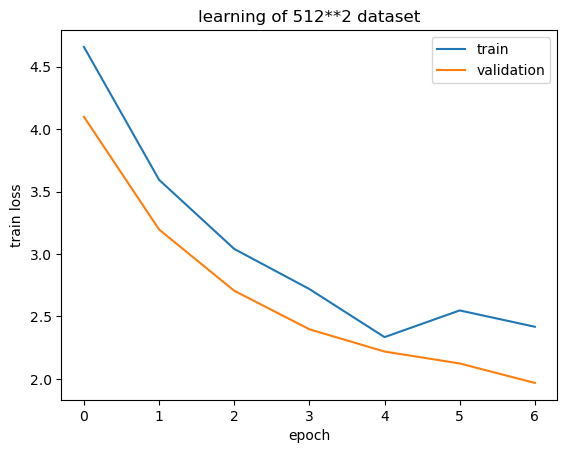

In [22]:
import pandas as pd
import seaborn as sns

df=pd.DataFrame()
df['epoch'] = list(range(NUM_EPOCHS))
df['validation loss'] = list(valid_loss)
df['train loss'] = list(total_loss)

sns.lineplot(x='epoch', y='train loss',data=df, label='train')
sns.lineplot(x='epoch', y='validation loss',data=df, label='validation')
plt.title('learning of '+str(image_size)+'**2 dataset')
plt.savefig('./output/'+'learning_curve_'+str(image_size)+'.png', dpi=300)
plt.show()

# TEST

In [23]:
import cv2
import io

In [24]:

def predict_single_frame(frame):
    images = cv2.resize(frame, IMAGE_SIZE, cv2.INTER_LINEAR)/255
    images = torch.as_tensor(images, dtype=torch.float32).unsqueeze(0)
    images = images.swapaxes(1, 3).swapaxes(2, 3)
    images = list(image.to(DEVICE) for image in images)
    
    with torch.no_grad():
      pred = model(images)
    
    colors = [(0,0,0),(1,0,0),(0,1,0),(1,1,1),(0,0,1)]
    im = images[0].swapaxes(0, 2).swapaxes(0, 1).detach().cpu().numpy().astype(np.float32)
    im2 = np.zeros_like(im).astype(np.float32)
    
    msk=pred[0]['masks'].detach().cpu().numpy()
    scr=pred[0]['scores'].detach().cpu().numpy()
    box=pred[0]['boxes'].detach().cpu().numpy()
    cell_ids=pred[0]['labels'].detach().cpu().numpy()
    
    dfx = pd.DataFrame()
    dfx['labels'] = cell_ids
    dfx['scores'] = scr
    dfx['width'] = [x2-x1 for x1,y1,x2,y2 in list(box)]
    dfx['height'] = [y2-y1 for x1,y1,x2,y2 in list(box)]
    area_w = [np.unique(k.flatten()>0.3, return_counts=True) for k in msk]
    area = [j[1][1] for j in area_w]
    dfx['area'] = area
    cell_types = ['boundary', 'vessel','ray','fiber', 'parenchyma']
    cell_type = [cell_types[n] for n in cell_ids]
    dfx['cell_name']= cell_type
    
    for i in range(len(pred[0]['masks'])):
        msk=pred[0]['masks'][i,0].detach().cpu().numpy()
        scr=pred[0]['scores'][i].detach().cpu().numpy()
        box=pred[0]['boxes'][i].detach().cpu().numpy()
        cell_name=pred[0]['labels'][i].detach().cpu().numpy()
        ####################
        
        if scr>0.05 :  #0.9
            #cv2.rectangle(im, (int(box[0]), int(box[1])), (int(box[2]), int(box[3])), colors[cell_type], 2)
            cv2.putText(im, str(cell_types[cell_name])+"_"+"{0:.2f}%".format(scr*100), (int(box[0]+5), int(box[1])+15), cv2.FONT_HERSHEY_SIMPLEX,
                        0.2, colors[cell_name], 1, cv2.LINE_AA)
            im2[:,:,0][msk> 0.37] = np.random.uniform(0,1)  # 0.87
            im2[:, :, 1][msk > 0.37] = np.random.uniform(0,1)
            im2[:, :, 2][msk > 0.37] = np.random.uniform(0,1)


    return (cv2.addWeighted(im, 0.5, im2, 0.5, 0)*255).astype(np.uint8),dfx, pred

def circle_plot(df):
    category_totals = df.groupby('cell_name')['area'].sum().reset_index()
    
    labels = category_totals['cell_name']
    sizes = category_totals['area']
    u, counts = np.unique(df['cell_name'], return_counts=True)
    colors = sns.color_palette('pastel')[0:len(labels)]
    
    items = [labels.values, labels]
    amount = [sizes.values, counts]
    comment = ['Occupied area of each cell','Number of each cell']
    
    fig, ax = plt.subplots(2,1,figsize=(4,4))
    for j in range(2):
        ax[j].pie(amount[j], labels=items[j], colors=colors, autopct='%1.1f%%', startangle=140)
        ax[j].axis('equal') 
        ax[j].set_title(comment[j])
    plt.tight_layout()
    plt.show()

def image_circle_plot(result,df, save_data=False):
    category_totals = df.groupby('cell_name')['area'].sum().reset_index()
    
    labels = category_totals['cell_name']
    sizes = category_totals['area']
    u, counts = np.unique(df['cell_name'], return_counts=True)
    colors = sns.color_palette('pastel')[0:len(labels)]
    
    items = [labels.values, labels]
    amount = [sizes.values, counts]
    comment = ['Occupied area of each cell','Number of each cell']

    plt.figure(figsize=(8,4))
    plt.subplot(121)
    plt.imshow(result)
    plt.axis('off')
    plt.subplot(222)
    plt.pie(amount[0], labels=items[0], colors=colors, autopct='%1.1f%%', startangle=140)
    plt.axis('equal') 
    plt.title(comment[0],fontsize=10)
    plt.subplot(224)
    plt.pie(amount[1], labels=items[1], colors=colors, autopct='%1.1f%%', startangle=140)
    plt.axis('equal') 
    plt.title(comment[1],fontsize=10)
    plt.tight_layout()
    if save_data == True:
        buf = io.BytesIO() # prepare buffer
        plt.savefig(buf, format='png') # store in the buffer
        enc = np.frombuffer(buf.getvalue(), dtype=np.uint8) # read from buffer
        dst = cv2.imdecode(enc, 1) # decoding
        dst = dst[:,:,::-1] # BGR->RGB
        plt.close()
        return dst
    else:
        plt.show()
    

In [25]:
from PIL import Image
model.train(False)

testfilename = [fl for fl in os.listdir(TEST_DIR) if fl.endswith('.png')]
i = 4
img0 = Image.open(os.path.join(TEST_DIR,testfilename[i])).convert('RGB')
img0 = np.array(img0)
img = cv2.imread(os.path.join(TEST_DIR,testfilename[i]))

result, dfx, pred = predict_single_frame(img)


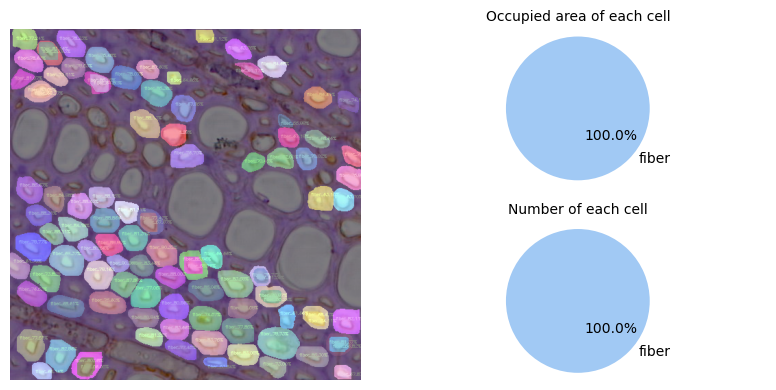

In [26]:
image_circle_plot(result, dfx)


In [27]:
print("The end of script.")

The end of script.


The end of script.

an appendix for gifmovie making

'''
imx = Image.open('./dataset/original/Alllit_test_original.png').convert('RGB')

# moving range
theta = 360
rad = np.deg2rad(theta)
drad = rad/100
r = 400

images = []
count = 0
for i in tqdm(range(360)):
    count += 1
    rsinθ = r * np.sin(-drad*count)
    rcosθ = r * np.cos(-drad*count)
    x = rcosθ
    y = rsinθ
    imxp = imx.crop((1250+x, 1250+y, 1250+x+image_size, 1250+y+image_size))
    result_frame, df, _ = predict_single_frame(np.array(imxp))
    dst = image_circle_plot(result_frame, df, save_data=True)
    images.append(dst)

import imageio
imageio.mimsave('./output/result'+str(image_size)+'stat.gif', images,'GIF', fps=5)
'''

 show segmented and detected mask area 

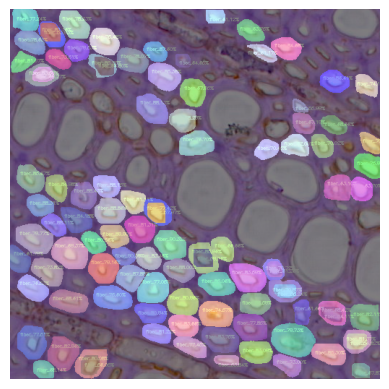

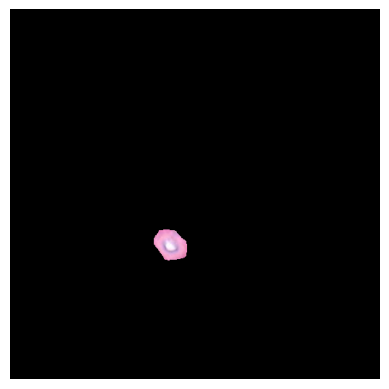

In [28]:
result, _, pred = predict_single_frame(img)
plt.imshow(result)
plt.axis('off')
plt.show()


each = pred[0]['masks'][0].detach().cpu().numpy()[0]
each_mask = np.zeros_like(img0)
for i in range(3):
    each_mask[:,:,i] = each > 0.3
img_out = img0*each_mask
plt.imshow(img_out) 
plt.axis('off')
plt.show()

In [29]:
#!ls ./checkpoint

In [30]:
'''
!cp ./checkpoint/256_Alllit_777_epoch.tar ./model/256_Alllit_777_epoch.tar
!cp ./checkpoint/512_Alllit_777_epoch.tar ./model/512_Alllit_777_epoch.tar
'''

'\n!cp ./checkpoint/256_Alllit_777_epoch.tar ./model/256_Alllit_777_epoch.tar\n!cp ./checkpoint/512_Alllit_777_epoch.tar ./model/512_Alllit_777_epoch.tar\n'

In [31]:
#!cp ./checkpoint/256_Alllit_777_epoch.tar ./model/256_Alllit_777_epoch.tar

The end of script.